# Designed hierarchy initialisations, part 2: one section per run

Continuation of `hierarchy_design_runs.ipynb` (runs 1-46 there), started on 2026-10-13 because that notebook had grown too big. **Runs
keep their global numbers** (41, then 47, 48, ... so that "run x" is unambiguous across notebooks and the session log); **sections are
numbered 1, 2, ...** Section 1 is run 41 (the 62-60-4 reduction of the anchor run 38), section 2 is run 47, and so on. The setup cell is
the first notebook's (registry, loaders, `findings_table`, `trajectory_plots`, `network_view`, `ensure_runs`), so every section runs on
its own after it.

Common ground for all runs here, unless a section says otherwise: depth-5 COB-ODT data (d = 100, tree seed 5178, 1M training points from
seed 5178, 200k test points from seed 999777); the **equivariant quadruple init** of runs 37-41 (30 probes and no spare rows, mutually
orthogonal and purely off-span; cues = pole x (v + u_j) renormalised and free; four second-layer units per node of types (block sign,
path sign) = (+,+), (+,-), (-,-), (-,+); the init is fixed by every tree flip up to a rotation of the off-span complement); SGD with
momentum 0.9, lr 0.01 -> 0.0005 cosine, batch 10k, 10 000 epochs of 100 steps, weight and momentum snapshots every 10 epochs.


In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import HIERARCHY_TARGETS, NODE_LEVEL, hierarchy_run_summary, probe_node_outcomes, plot_probe_target_cosines, probe_deviation_lineage
from layer_lenses.relu_analysis import (snapshot_state_dict, first_layer_odt_alignment, first_layer_alignment_series,
                                         plot_first_layer_alignment_series, plot_layered_relu_graph)
from layer_lenses.init_sweep import SweepRunSpec, build_data, build_tree
from layer_lenses.relu_mlp import ReLUMLP
from layer_lenses.relu_analysis import load_designed_run


RESULTS = Path("../results/designed_init")
tree = build_tree(SweepRunSpec(tree_seed=5178, data_seed=0, init_seed=0, batch_size=1))
x_test, y_test = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree)
X_test = torch.from_numpy(x_test).float()


def load_hier_run(folder, tag, dims):
    """Trajectory (all layers every 10 epochs), per-epoch table and summary row of one run."""
    z = np.load(RESULTS / folder / "runs" / f"{tag}.npz")
    summ = pd.read_csv(RESULTS / folder / "summary.csv")
    return {"tag": tag, "dims": dims, "epochs": z["epochs"], "losses": z["epoch_losses"], "lr": z["lr_history"],
            "W": {k[3:]: z[k] for k in z.files if k.startswith("w__")}, "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{tag}.csv"),
            "summary": summ[summ.tag == tag].iloc[0]}


def logits_at(run, epoch):
    m = ReLUMLP(input_dim=100, hidden_dims=run["dims"], bias=False); m.load_state_dict(snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)); m.eval()
    with torch.no_grad():
        return m(X_test).reshape(-1).numpy()


def findings_table(run):
    """End-of-run numbers: loss, both test-error rules, zero-logit fraction, coverage and probe outcomes."""
    out = logits_at(run, int(run["epochs"][-1])); W1 = run["W"]["hidden_layers.0.weight"]
    s = hierarchy_run_summary(W1[-1], tree); L = run["losses"]; first = lambda t: int(np.nonzero(L <= t)[0][0] + 1) if (L <= t).any() else None
    rec = {"final epoch loss": round(float(L[-1]), 4), "test error (logit >= 0)": round(float(((out >= 0) != (y_test > 0)).mean()), 4), "test error (strict)": round(float(((out > 0) != (y_test > 0)).mean()), 4),
           "zero-logit fraction": round(float((out == 0).mean()), 3), "negative output weights": int((run["W"]["output_layer.weight"][-1] < 0).sum()),
           "epochs to 0.3 / 0.1 / 0.05": f"{first(0.3)} / {first(0.1)} / {first(0.05)}", "aligned rows": f"{s['aligned_rows']} / {s['rows']}", "nodes covered": f"{s['nodes_covered']} / 31, missing {s['missing_nodes']}",
           "own-probe nodes / intended / opposite": f"{s['own_probe_nodes']} / {s['intended_pole']} / {s['opposite_pole_only']}", "missed by own probes": s["missed_by_own_probes"], "both poles": s["both_poles"]}
    display(pd.Series(rec).to_frame(run["tag"]))
    return s


def trajectory_plots(run, neuron_ids, node_ids=None, start_epoch=None, end_epoch=None):
    """Loss / test error / coverage over epochs; every probe's cosine to its target; alignment series of chosen neurons.

    ``start_epoch`` / ``end_epoch`` (inclusive, in the run's own epoch units) restrict every panel to the
    snapshots and loss values inside that window; None means from the first / to the last.
    """
    ep_all = run["epochs"]; lo = ep_all[0] if start_epoch is None else start_epoch; hi = ep_all[-1] if end_epoch is None else end_epoch
    sel = (ep_all >= lo) & (ep_all <= hi)
    if not sel.any():
        raise ValueError(f"no snapshots in epochs [{lo}, {hi}]; stored epochs run {ep_all[0]}..{ep_all[-1]} every {ep_all[1] - ep_all[0]}")
    ep = ep_all[sel]; W1 = run["W"]["hidden_layers.0.weight"][sel]; W2 = run["W"]["hidden_layers.1.weight"][sel]
    loss_epochs = np.arange(1, len(run["losses"]) + 1); lsel = (loss_epochs >= max(lo, 1)) & (loss_epochs <= hi)
    cov, err = [], []
    for i, e in enumerate(ep):
        cov.append(hierarchy_run_summary(W1[i], tree)["nodes_covered"]); err.append(float(((logits_at(run, int(e)) >= 0) != (y_test > 0)).mean()))   # test error (logit >= 0 rule) at every stored checkpoint
    window = "" if start_epoch is None and end_epoch is None else f" (epochs {lo}-{hi})"
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
    axes[0].plot(loss_epochs[lsel], np.asarray(run["losses"])[lsel]); axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss")
    axes[1].plot(ep, err); axes[1].set_yscale("log"); axes[1].set_ylabel("test error (logit >= 0)")
    axes[2].plot(ep, cov); axes[2].axhline(31, color="k", ls=":", lw=0.8); axes[2].set_ylabel("nodes covered (|cos| > 0.95)")
    for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.25)
    fig.suptitle(f"{run['tag']}{window}", fontsize=9); fig.tight_layout(); plt.show()
    plot_probe_target_cosines(W1, ep, tree, title=f"{run['tag']}{window}: signed cosine of each probe to its designed target"); plt.show()
    if node_ids is None:
        W_end = W1[-1]; C = (W_end / np.linalg.norm(W_end, axis=1, keepdims=True)) @ tree.w_list.T
        node_ids = sorted({HIERARCHY_TARGETS[i][0] for i in neuron_ids if i < 30} | {int(np.abs(C[i]).argmax()) for i in neuron_ids})
    series = first_layer_alignment_series(W1, ep, tree, neuron_ids=neuron_ids, node_ids=node_ids, fan_out_weights=W2)
    plot_first_layer_alignment_series(series, title=f"{run['tag']}{window}: first-layer neurons {neuron_ids} vs ODT nodes {node_ids}"); plt.show()
    return series


def network_view(run, epoch, *, align_threshold=0.5, edge_threshold=0.5, only_aligned_first_layer=False, figsize=(14, 18), mask_arg=None, even_odd_layer3=False, layer_orders=None):
    """Layered graph at one epoch (first-layer rows labelled by closest ODT node) and the row -> node table.

    even_odd_layer3=True draws the third hidden layer with all even neurons first (top) and all odd neurons after them (display only;
    labels keep the neuron indices). layer_orders={layer_index: order} gives any other top-to-bottom order per hidden layer (0-based).
    """
    if even_odd_layer3:
        n3 = run["W"]["hidden_layers.2.weight"].shape[1]; layer_orders = {**(layer_orders or {}), 2: list(range(0, n3, 2)) + list(range(1, n3, 2))}
    sd = snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)
    mask = None
    if only_aligned_first_layer:
        al = first_layer_odt_alignment(state_dict=sd, tree=tree)
        mask = [al["max_abs_cos"].numpy() >= align_threshold] + [np.ones(sd[f"hidden_layers.{i}.weight"].shape[0], dtype=bool) for i in (1, 2)]    
    if mask_arg is not None:
        mask = mask_arg
    alignment, _, fig, ax = plot_layered_relu_graph(state_dict=sd, tree=tree, depth=5, epoch=epoch, node_mask=mask, alignment_abs_threshold=align_threshold, edge_abs_threshold=edge_threshold, figsize=figsize, layer_orders=layer_orders)
    plt.show()
    n = sd["hidden_layers.0.weight"].shape[0]
    tab = pd.DataFrame({"row": np.arange(n), "group": ["probe"] * 30 + ["cue"] * 32 + ["random"] * (n - 62), "designed_target": [HIERARCHY_TARGETS[i] if i < 30 else "" for i in range(n)],
                        "closest_node": alignment["closest_odt_np"], "level": alignment["node_level"], "signed_cos": alignment["signed_closest_cos"].numpy().round(3), "norm": alignment["row_norms"].numpy().round(2)})
    display(tab[tab.signed_cos.abs() >= align_threshold].sort_values(["level", "closest_node", "signed_cos"]).reset_index(drop=True))
    return tab

# --- run registry: how every run of this notebook is loaded, so any section can be run on its own after this cell ---
RUN_REGISTRY = {41: ("replay", "hierarchy_equivariant_60_nospare_l3x4", [62, 60, 4]),        # section 1: the 62-60-4 reduction of the anchor run 38
                47: ("replay", "hd2_run2_l3x2_kaiming", [62, 60, 2]),                        # section 2: two third-layer neurons, Kaiming rows, uniform lr
                48: ("replay", "hd2_run48_l3x2_readout", [62, 60, 2]),                       # section 3: run 47 with the readout rescaled to run 41's
                49: ("replay", "hd2_run49_l3x2_readout_10M", [62, 60, 2]),                  # section 4: run 48 with 10M points (same 1M steps)
                50: ("replay", "hd2_run50_pluscues_10M", [46, 60, 2]),                   # section 5: run 49 with the 16 +u_j cues only
                51: ("replay", "hd2_run51_phased_10M", [62, 60, 2]),                     # section 6: run 49 with phased freezing (cues 0-500, probes 500-1000, free 1000-1200)
                52: ("replay", "hd2_run52_phased2_cue05_10M", [62, 60, 2]),              # section 7: cue bias 0.5, two phases (cues frozen 0-500, free 500-1000)
                53: ("replay", "hd2_run53_phased2_cue1_10M", [62, 60, 2]),               # section 8: the bias-1 control of run 52
                54: ("replay", "hd2_run54_phased2_w2neg_10M", [62, 60, 2])}               # section 9: run 53 with W2 negated at init

def load_replay_run(folder, dims):
    """(seed_result, run dict) of a replayable run written by save_designed_run: trajectories of all layers every 10 epochs, losses, lr, tables."""
    sr = load_designed_run(RESULTS / folder / "replay"); _out = sr["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
    run = {"tag": sr["tag"], "dims": dims, "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
           "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
           "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{sr['tag']}.csv"), "summary": pd.read_csv(RESULTS / folder / "summary.csv").iloc[0]}
    return sr, run


def ensure_runs(*numbers):
    """Load every listed run that is not in the notebook namespace yet (as run<n>, plus sr<n> for replayable runs); returns {n: run<n>}.

    Cross-run cells at the end of a section call this, so a section can be run on its own after a kernel restart and this cell.
    """
    g = globals(); loaded = {}
    for n in numbers:
        if f"run{n}" not in g:
            kind, *spec = RUN_REGISTRY[n]
            if kind == "hier":
                g[f"run{n}"] = load_hier_run(*spec)
            else:
                g[f"sr{n}"], g[f"run{n}"] = load_replay_run(*spec)
            print(f"ensure_runs: loaded run {n} ({spec[0]})")
        loaded[n] = g[f"run{n}"]
    return loaded


## 1. Run 41: the 62-60-4 reduction of the anchor run 38

| setting | value |
|---|---|
| init | run 38's (62-60-40 equivariant quadruples) with the third layer replaced by its four distinct neurons (S, +) x15, (S, -) x5, (Sc, +) x5, (Sc, -) x15, S reading the path-sign-+ units; the multiplicity m is folded into the output weight (m x 0.2236) and into gradient scales (m on the output weight, 1/m on the W3 row) |
| protocol | SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hierarchy_equivariant_60_nospare_l3x4/replay/` |
| script | `run_hierarchy_equivariant60.py --no-spare --reduced-l3` |

**Findings** (from the first notebook, section 41). Loss 0.0033, test error 0.49%, all 31 nodes, 29 of 30 probes on their own node, no spikes; identical to run 38 until float-32 chaos separates them (weights within 3e-5 at epoch 10, 1% at epoch 300). The output weights end at 80.1 / 18.1 / -19.7 / -84.7: the two 5-copy classes flip their output sign and end as weaker versions of the 15-copy classes, which motivates run 2.


In [ ]:
sr41, run41 = load_replay_run("hierarchy_equivariant_60_nospare_l3x4", [62, 60, 4])          # ~20 s
summary41 = findings_table(run41)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series41 = trajectory_plots(run41, NEURON_IDS, node_ids=None, end_epoch=10000)

In [ ]:
GRAPH_EPOCH = 0
table41 = network_view(run41, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 2. Run 47: two third-layer neurons, Kaiming scale in every layer, uniform learning rate (62-60-2)

| setting | value |
|---|---|
| init | run 41's with the two redundant third-layer neurons (the 5-copy classes, which flip sign) removed: W3 = [S; Sc] with 30 entries of sqrt(2/30) = 0.258 per row, output (+1, -1); every layer's rows have norm sqrt(2) (W1 and W2 already did). The effective output weight per unit is +-0.258 (run 41: +-0.816). No gradient scales, nothing frozen |
| protocol | SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hd2_run2_l3x2_kaiming/replay/` |
| script | `run_hd2_l3x2.py --out hd2_run2_l3x2_kaiming --tag hd2_run2_l3x2_kaiming_seed0` (the folder keeps its pre-renumbering name) |

**Findings.**
- Loss 0.0102, test error 0.71%, 29 of 31 nodes, no spikes, 28 min; run 41: 0.0033 / 0.49% / 31. Slower throughout: loss 0.1 at epoch 1039 (run 41: 418), 0.05 at 2611 (716), never below 0.01 (5326).
- Fates: 19 of 30 probes on their own node (run 41: 28); 8 deviations, all level-3 probes going to a child level-4 node (-u_7 -> u_16, +u_8 -> -u_17, ..., +u_14 -> -u_29), 0 unrelated, and three level-3 probes short of capture; the cues end 10 on their own normal and 13 on ancestors (run 41: 23 / 7). The lineage rule holds; the level-3 / level-4 competition is lost more often.
- Two third-layer neurons are enough: the output ends at (+21.3, -21.2) and W3 entries reach 5.5, a readout as large as run 41's (|w_eff| 76 vs 110). What the run lacks is the *initial* readout scale: the Kaiming rows give an effective output weight of +-0.258 per unit against run 41's +-0.816, and since the factorised readout grows at a rate set by its own size, the early phase is six times slower (|w_eff| 5.4 vs 33 at epoch 100, 49 vs 86 at epoch 1000). The first layer catches up only partly (level-3 own-coordinate spread 0.07 / 1.55 / 4.1 at epochs 200 / 1000 / 10000 vs 0.49 / 3.4 / 5.2).
- So the reduction to two neurons costs nothing in principle, and the gap to run 41 is a readout-scale effect: a run 3 with the same two-neuron Kaiming design but the readout scaled to +-0.816 (output +-sqrt(10), or W3 rows at norm 2 sqrt 2) would separate the two (run 48).


In [ ]:
sr47, run47 = load_replay_run("hd2_run2_l3x2_kaiming", [62, 60, 2])          # ~20 s
summary47 = findings_table(run47)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series47 = trajectory_plots(run47, NEURON_IDS, node_ids=None, end_epoch=10000)

In [ ]:
GRAPH_EPOCH = 1000
table47 = network_view(run47, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 41 and 47 (loads run 41 if needed). Loss, fates, the two output weights and the effective output scale against run 1.
ensure_runs(41)
from layer_lenses.designed_init import probe_deviation_lineage
_rows = []
for n in [41, 47]:
    r = globals()[f"run{n}"]; W = r["W"]; lin = probe_deviation_lineage(W["hidden_layers.0.weight"][-1], tree); s = r["summary"]; L = r["losses"]; d = np.abs(np.diff(np.log(L)))
    w_eff = W["output_layer.weight"][:, 0, :] @ W["hidden_layers.2.weight"]
    _rows.append({"run": n, "dims": r["dims"], "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes own node": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()),
                  "spiky epochs": int((d > 0.3).sum()), "epoch to 0.1 / 0.05 / 0.01": f"{int(s['epoch_to_0.1'])} / {int(s['epoch_to_0.05'])} / {int(np.argmax(L <= 0.01)) + 1 if (L <= 0.01).any() else -1}",
                  "w_out end": np.round(W["output_layer.weight"][-1][0], 2).tolist(), "|w_eff| ep 100 / 1000 / end": " / ".join(f"{np.abs(w_eff[int(np.searchsorted(r['epochs'], e))]).mean():.1f}" for e in (100, 1000, int(r["epochs"][-1])))})
print(pd.DataFrame(_rows).to_string(index=False))
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [41, 47]]; plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 3. Run 48: run 47 with the readout rescaled to run 41's

| setting | value |
|---|---|
| init | run 47's (62-60-2, uniform lr) with the readout rescaled: W3 entries e = 1.633 (rows S, Sc at norm 8.9), output w = +-0.5, so the effective output weight per unit is e w = +-0.816 as in run 41 **and** the factorised readout's shared-mode rate at init, lr x (30 e^2 + 2 w^2) = 80.5 lr, matches run 41's full model (30 x 2.67 + 2 = 82); run 47 had 4, and either single-layer rescaling to +-0.816 (e = 0.816, w = 1 or e = 0.258, w = 3.16) would give 22. Logit rms at init 0.049 (run 41: 0.049, run 47: 0.016) |
| protocol | run 47's: SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hd2_run48_l3x2_readout/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5` |

**Findings.**
- Loss 0.0029, test error 0.46%, all 31 nodes, no spikes, 27 of 30 probes on their own node (3 level-3 probes to a child: +u_10 -> u_21, +u_13 -> -u_27, +u_14 -> -u_29), cues 21 own / 6 on ancestors. This is run 41 (0.0033 / 0.49%, 31 nodes, 28 probes) reproduced by a 62-60-2 network with a uniform learning rate.
- Not only the end state: the trajectory statistics coincide with run 41's. Loss 0.1 at step 41 400 (run 41: 41 800), 0.05 at 71 800 (71 600); |w_eff| 33.8 / 86.0 / 110.6 at 10k / 100k / 1M steps (33.4 / 85.9 / 110.3); level-3 own-coordinate spread 0.50 / 3.38 / 5.28 (0.49 / 3.37 / 5.23). The two neurons end at (+22.2, -23.6).
- So the four-neuron layer, its multiplicities and the gradient scales were all stand-ins for two numbers: the effective output weight per unit (+-0.816) and the readout's shared-mode rate at init (30 e^2 + 2 w^2 = 80.5 vs 82). With those matched, run 47's gap (0.0102, 19 probes) closes completely. The anchor's dynamics live in a 62-60-2 model with one learning rate.


In [ ]:
sr48, run48 = load_replay_run("hd2_run48_l3x2_readout", [62, 60, 2])          # ~20 s
summary48 = findings_table(run48)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series48 = trajectory_plots(run48, NEURON_IDS, node_ids=None, end_epoch=int(run48["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table48 = network_view(run48, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 4. Run 49: run 48 with ten times the data (10M points, same 1M steps)

| setting | value |
|---|---|
| init | run 48's |
| protocol | 10M training points (seed 5178, chunked), batch 10k, 1000 epochs of 1000 steps: the same 1M steps and the same cosine schedule in step units as run 48; each point is seen 100 times instead of 1000; snapshots every epoch (1000 steps, as before) |
| storage | `results/designed_init/hd2_run49_l3x2_readout_10M/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5 --n-train 10000000 --epochs 1000 --snap 1` |

**Findings.**
- With ten times the data and the same 1M steps: test error 0.17% (run 48: 0.46%), all 31 nodes, **all 30 probes on their own node, no deviations**, no spikes; the final epoch-mean training loss is 0.0055 (run 48: 0.0029, which is the 1M-point sample being fitted: its test error is 2.7x worse). The cues end 21 on their own normal and 11 on ancestors.
- Faster, not slower: loss 0.1 at step 39 000 (run 48: 41 400), 0.05 at 55 000 (71 800), 0.01 at 520 000 (393 000, but on a loss that keeps falling with the sample). |w_eff| 32 / 85 / 102 at 10k / 100k / 1M steps, run 48's growth.
- **The level-3 symmetry breaking almost disappears.** The within-class spread of the level-3 probes' own coordinate is 0.14 / 0.25 / 0.34 at 20k / 100k / 1M steps against 0.50 / 3.38 / 5.28 in run 48, and the level-3 residual (in-span components that must vanish on the symmetric subspace) ends at 0.005 vs 0.019; the level-3 probes stay congruent to the end and every one of them captures its node. With the sample's asymmetry reduced by sqrt(10), the fringe fates that varied from run to run are gone, which identifies them as sample-induced and the infinite-data solution as the fully symmetric one: every probe on its node, the symmetric subspace never left.


In [ ]:
sr49, run49 = load_replay_run("hd2_run49_l3x2_readout_10M", [62, 60, 2])          # ~20 s
summary49 = findings_table(run49)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series49 = trajectory_plots(run49, NEURON_IDS, node_ids=None, end_epoch=int(run49["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table49 = network_view(run49, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 41, 47, 48 and 49 (loads the missing ones). Readout scale and data size: loss, fates, output growth, congruence. x axis in steps for run 49.
ensure_runs(41, 47, 48)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
_rows = []
for n in [41, 47, 48, 49]:
    r = globals()[f"run{n}"]; W = r["W"]; sr = globals()[f"sr{n}"]; steps_per_epoch = int(sr["data_spec"]["n_train"]) // 10_000; lin = probe_deviation_lineage(W["hidden_layers.0.weight"][-1], tree); s = r["summary"]; L = r["losses"]; d = np.abs(np.diff(np.log(L)))
    w_eff = W["output_layer.weight"][:, 0, :] @ W["hidden_layers.2.weight"]; cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W["hidden_layers.0.weight"][0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W["hidden_layers.0.weight"][-1] / np.linalg.norm(W["hidden_layers.0.weight"][-1], axis=1, keepdims=True) @ tree.w_list.T
    summ = symmetric_class_summary(symmetric_coordinates(W["hidden_layers.0.weight"][-1].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    _rows.append({"run": n, "points": sr["data_spec"]["n_train"], "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "unrelated": int((lin.relation == "unrelated").sum()),
                  "cues own / anc": f"{sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95)} / {sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0]))}", "spiky": int((d > 0.3).sum()),
                  "step to loss 0.1 / 0.05": f"{int(s['epoch_to_0.1']) * steps_per_epoch} / {int(s['epoch_to_0.05']) * steps_per_epoch}", "|w_eff| at 10k / 100k steps / end": " / ".join(f"{np.abs(w_eff[int(np.searchsorted(r['epochs'] * steps_per_epoch, st))]).mean():.1f}" for st in (10_000, 100_000, 1_000_000)),
                  "L3 own spread end": round(float(summ.loc["probe_L3", "own_spread"]), 2)})
print(pd.DataFrame(_rows).to_string(index=False))
plt.figure(figsize=(9, 3.5))
for n in [41, 47, 48, 49]:
    r = globals()[f"run{n}"]; spe = int(globals()[f"sr{n}"]["data_spec"]["n_train"]) // 10_000; plt.plot(np.arange(1, len(r["losses"]) + 1) * spe, r["losses"], lw=0.7, label=f"run {n}")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("epoch-mean loss"); plt.legend(); plt.show()

## 5. Run 50: run 49 with only the 16 cues on +u_j (46-60-2)

| setting | value |
|---|---|
| init | run 49's with the 16 minus-pole cue rows (-u_j) removed: 30 probes + 16 cues on +(v + u_j). Each unit's cue block keeps its coefficients on the remaining cues (-side x c), so it is no longer the linear feature c x (sum of a_m on the left - sum on the right) but a sum of relu(v + u_m) terms; the W2 rows are rescaled back to norm sqrt(2) (they had dropped to 1.22). Readout e = 1.633, w = +-0.5 as in runs 48-49. The tree flips still fix the init (worst deviation 2e-15: flips never negate a level-4 normal); the label-negation symmetry, which paired each cue with its twin, is gone. Logit rms at init 0.039 (run 49: 0.049) |
| protocol | run 49's: 10M points, batch 10k, 1000 epochs of 1000 steps, SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, snapshots every epoch |
| storage | `results/designed_init/hd2_run50_pluscues_10M/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5 --plus-cues-only --n-train 10000000 --epochs 1000 --snap 1` |
| question | the +-u_j cue pairs may be redundant (a level-4 node needs only one of its two poles captured for a good loss), which would explain why some cues, despite starting at cosine 0.46 with their normal, never capture it. With one cue per level-4 node, do all 16 capture their own normal? |

**Findings.**
- Loss 0.0222, test error 0.59%, 27 of 31 nodes (14 of 16 level-4 nodes), no spikes; run 49: 0.0055 / 0.17% / 31 / 16. Four times slower: loss 0.1 at step 144 000 (run 49: 39 000), 0.05 at 504 000 (55 000), never 0.01.
- **Cues: 10 of 16 on their own normal, 1 on an ancestor, 5 stuck between (|cos| 0.6-0.7 with a normal, cue 22's probe-like row nearest to u_1).** With two cues per node (run 49) 21 of 32 ended on their own normal and 11 climbed to an ancestor, and every level-4 node kept at least one cue: the pairs were redundant for coverage, and the surplus cue of 11 pairs was reassigned to an internal node. With one cue per node nothing can leave without uncovering a level-4 node, so only one climbs, five stall, and two level-4 nodes end uncovered. Capture is also slower (0 of 16 on their normal at epoch 30 vs 16 of 32, 8 of 16 at epoch 50).
- **Probes: 20 of 30 on their own node** (run 49: 30 of 30): four level-3 probes go to a child (-u_9 -> u_20, +u_10 -> u_22, -u_11 -> u_24, +u_12 -> u_25) and six stay short of capture; probe capture is slower too (6 of 30 at epoch 30 vs 14). The level-3 symmetry breaking is back despite the 10M points: level-3 own-coordinate spread 6.4 (run 49: 0.34).
- Reading: the +-cue pairs are redundant for level-4 coverage, as suspected, but that redundancy is what the design uses: the surplus cues become the internal-node rows the probes fail to supply, and the paired block gives each unit an exactly linear level-4 feature; with the twins gone the blocks are half-rectified, the probes capture later, the level-3 competition is lost to the sample's fluctuations again, and the loss is 4x worse. The label-negation symmetry is gone as well: the output ends at (+25.8, -10.9) against run 49's (+24.4, -18.9).


In [ ]:
sr50, run50 = load_replay_run("hd2_run50_pluscues_10M", [46, 60, 2])          # ~20 s
summary50 = findings_table(run50)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series50 = trajectory_plots(run50, NEURON_IDS, node_ids=None, end_epoch=int(run50["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 1000
table50 = network_view(run50, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 49 and 50 (loads run 49 if needed). Cue fates with 32 vs 16 cues: own normal, ancestor, other, diffuse; probe fates; loss.
ensure_runs(49)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors
_rows = []
for n in [49, 50]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    kinds = {"own": 0, "ancestor": 0, "other level-4": 0, "diffuse": 0}; where = []
    for rr in cr:
        top = int(abs(C[rr]).argmax()); c = float(C[rr][top]); m, q = inv[rr]
        if abs(c) <= 0.95: kinds["diffuse"] += 1
        elif top == m: kinds["own"] += 1
        elif top in node_ancestors(m): kinds["ancestor"] += 1; where.append((m, q, top, round(c, 2)))
        else: kinds["other level-4"] += 1; where.append((m, q, top, round(c, 2)))
    _rows.append({"run": n, "cues": len(cr), "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "level-4 nodes covered": len(set(k for k in np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95] if k >= 15)),
                  "probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), **{f"cues {k}": v for k, v in kinds.items()}, "cues elsewhere (node, pole, end, cos)": where})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(8, 3)); [plt.plot(np.arange(1, len(globals()[f"run{n}"]["losses"]) + 1) * 1000, globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [49, 50]]; plt.xscale("log"); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("epoch-mean loss"); plt.legend(); plt.show()

## 6. Run 51: run 49 with a phased protocol (cues frozen, then probes frozen, then everything free)

| setting | value |
|---|---|
| init | run 49's (62-60-2, orthogonal off-span probes, cues pole x (v + u_j), readout e = 1.633 / w = 0.5; anchor run as of 2026-10-14) |
| protocol | 10M points, batch 10k, 1000 steps per epoch, SGD momentum 0.9, one cosine schedule lr 0.01 -> 0.0005 over the 1200 epochs; **epochs 0-500: the 32 cue rows frozen** (probes, W2, W3, output train); **epochs 500-1000: the 30 probe rows frozen** (cues and the rest train); **epochs 1000-1200: nothing frozen**. Three chained segments (`stop_epoch`, `start_epoch`, the previous segment's optimizer state), momentum buffers and schedule continuous across the phase changes, snapshots every epoch, saved as one replayable run |
| storage | `results/designed_init/hd2_run51_phased_10M/replay/` |
| script | `run_hd2_phased.py --out hd2_run51_phased_10M --tag hd2_run51_phased_10M_seed0` (`--phases 500 500 200`) |

**Findings.**
- **The designed solution, exactly: all 30 probes on their own node, all 32 cues on their own normal, 0 on ancestors, all 31 nodes covered**, test error 0.12% (run 49: 0.17%, the best so far), final loss 0.0050 (0.0055), no spikes. The level-3 within-class spread ends at 0.08 (run 49: 0.34): the most symmetric end state of the series.
- Phase 1 (cues frozen, epochs 0-500): the probes capture all 30 nodes by epoch 40, earlier than in run 49 (10 captured at epoch 20 vs 2), but the loss plateaus at 0.07-0.11 with only 15 nodes covered, since the frozen cues sit at cosine 0.46 with their normals and nothing holds the level-4 nodes. The readout still grows to 100.
- Phase 2 (probes frozen, 500-1000): every cue goes to its own normal (own coordinate 0.65 -> 1.78 by epoch 700 -> 2.30), none climbs: with the probes already on the internal nodes there is no vacancy for a surplus cue to fill. Loss 0.011 at epoch 1000.
- Phase 3 (all free, 1000-1200, lr 0.0012 -> 0.0005): loss 0.011 -> 0.0050, nothing moves off its node.
- Reading: the 11 cues that climbed to ancestors in run 49 were a competition artefact of simultaneous training (cues reaching internal nodes while the probes were still travelling), not a feature the solution needs; ordering the two row types gives the design's intended assignment with a better test error, and run 51's end state is the natural target for the population-flow description (one representative per class with essentially zero spread). The cost is time: loss 0.1 at step 153 000 and 0.05 at 586 000 against 39 000 / 55 000, because phase 1 cannot go below 0.07 without the cues.


In [ ]:
sr51, run51 = load_replay_run("hd2_run51_phased_10M", [62, 60, 2])          # ~20 s
summary51 = findings_table(run51)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series51 = trajectory_plots(run51, NEURON_IDS, node_ids=None, end_epoch=int(run51["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table51 = network_view(run51, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 49 and 51 (loads run 49 if needed). Loss and first-layer fates by phase: where the probes and cues stand at epochs 500, 1000 and 1200 against run 49 at the same step counts.
ensure_runs(49)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
def fates_at(run, sr, epoch):
    W = run["W"]["hidden_layers.0.weight"]; i = int(np.searchsorted(run["epochs"], epoch)); cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[i], tree)
    summ = symmetric_class_summary(symmetric_coordinates(W[i].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    return {"probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "probes captured": int((np.abs(C[:30]).max(1) > 0.95).sum()), "cues own": sum(1 for r in cr if abs(C[r]).argmax() == inv[r][0] and abs(C[r]).max() > 0.95),
            "cues on ancestor": sum(1 for r in cr if abs(C[r]).max() > 0.95 and abs(C[r]).argmax() in node_ancestors(inv[r][0])), "nodes": len(set(np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95])), "L3 own spread": round(float(summ.loc["probe_L3", "own_spread"]), 2),
            "loss": round(float(run["losses"][max(epoch - 1, 0)]), 4)}
rows = []
for n in [49, 51]:
    for e in [100, 300, 500, 700, 1000, int(globals()[f"run{n}"]["epochs"][-1])]:
        rows.append({"run": n, "epoch": e, **fates_at(globals()[f"run{n}"], globals()[f"sr{n}"], e)})
print(pd.DataFrame(rows).to_string(index=False))
plt.figure(figsize=(9, 3.5)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [49, 51]]; [plt.axvline(v, color="k", lw=0.5, ls="--") for v in (500, 1000)]; plt.yscale("log"); plt.xlabel("epoch (1000 steps)"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 7. Run 52: cue bias halved (v + 0.5 u_j), two phases (cues frozen for 500 epochs, then everything free)

| setting | value |
|---|---|
| init | run 49's with the cues at pole x (v + 0.5 u_j) renormalised: cosine 0.36 with their own normal instead of 0.46, and every unit's linear cue feature half as strong (logit rms at init 0.026, run 49: 0.049). Readout e = 1.633 / w = 0.5 |
| protocol | 10M points, 1000 steps per epoch, SGD momentum 0.9, one cosine schedule lr 0.01 -> 0.0005 over 1000 epochs (as run 49); **epochs 0-500: cue rows frozen; epochs 500-1000: nothing frozen** (run 51's middle phase, probes frozen, dropped as redundant) |
| storage | `results/designed_init/hd2_run52_phased2_cue05_10M/replay/` |
| script | `run_hd2_phased.py --cue-bias 0.5 --phases 500 500` |

**Findings.**
- Loss 0.038, test error 1.1%, all 31 nodes, all 30 probes on their own node, 30 of 32 cues on their own normal (the other two at |cos| 0.95), none on an ancestor; one transient at the phase change (0.071 -> 0.097 at epoch 520). Far from run 51 (0.0050 / 0.12%).
- Phase 1 (cues frozen) is run 51's: all 30 probes captured by epoch 40 (2 at epoch 20), plateau at 0.071 with 15 nodes covered. The half-strength cue feature does not slow the probes.
- Phase 2 is where the halved bias shows: the cues reach their normals slowly, mean |cos| with the own normal 0.36 -> 0.42 (epoch 520) -> 0.47 (600) -> 0.55 (700) -> 0.97 (1000), and only cross 0.95 in the last epochs, so the loss has no time to fall (0.061 at epoch 700, 0.038 at 1000). In run 51 the release phase brought the cues from 0.46 to 1.00 and the loss to 0.011 within 500 epochs. While rotating onto their normals the cue rows shed their v component and shrink (own-normal coordinate 0.57 -> 0.41 even as the cosine rises).
- Caveat: two things changed against run 51's release phase. The cue bias (0.5 vs 1) and the learning rate, since run 52's phase 2 runs over epochs 500-1000 of a 1000-epoch cosine (lr 0.0053 -> 0.0005) while run 51's ran over 500-1000 of a 1200-epoch one (0.0065 -> 0.0011). A control with bias 1 under run 52's two-phase 1000-epoch schedule would separate the two; with the slow capture here, the bias looks like the larger effect, but it is not isolated.


In [ ]:
sr52, run52 = load_replay_run("hd2_run52_phased2_cue05_10M", [62, 60, 2])          # ~20 s
summary52 = findings_table(run52)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series52 = trajectory_plots(run52, NEURON_IDS, node_ids=None, end_epoch=int(run52["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table52 = network_view(run52, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 49, 51 and 52 (loads the missing ones). Fates by phase; the cue own-normal coordinate; loss.
ensure_runs(49, 51)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
def fates_at(run, sr, epoch):
    W = run["W"]["hidden_layers.0.weight"]; i = int(np.searchsorted(run["epochs"], epoch)); cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[i] / np.linalg.norm(W[i], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[i], tree)
    summ = symmetric_class_summary(symmetric_coordinates(W[i].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    return {"probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "cues own": sum(1 for r in cr if abs(C[r]).argmax() == inv[r][0] and abs(C[r]).max() > 0.95), "cues on ancestor": sum(1 for r in cr if abs(C[r]).max() > 0.95 and abs(C[r]).argmax() in node_ancestors(inv[r][0])),
            "nodes": len(set(np.abs(C).argmax(1)[np.abs(C).max(1) > 0.95])), "L3 own spread": round(float(summ.loc["probe_L3", "own_spread"]), 2), "cue own coord": round(float(summ.loc["cue_+", "own"]), 2), "loss": round(float(run["losses"][max(epoch - 1, 0)]), 4)}
rows = [{"run": n, "epoch": e, **fates_at(globals()[f"run{n}"], globals()[f"sr{n}"], e)} for n in [49, 51, 52] for e in [40, 100, 300, 500, 600, 700, 1000, int(globals()[f"run{n}"]["epochs"][-1])] if e <= globals()[f"run{n}"]["epochs"][-1]]
print(pd.DataFrame(rows).to_string(index=False)); print({n: f"test error {float(globals()[f'run{n}']['summary'].test_error_end):.4f}" for n in [49, 51, 52]})
plt.figure(figsize=(9, 3.5)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [49, 51, 52]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch (1000 steps)"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 8. Run 53: the bias-1 control of run 52 (two phases, 1000-epoch schedule)

| setting | value |
|---|---|
| init | run 49's (cue bias 1: cues at pole x (v + u_j), cosine 0.46 with their normal) |
| protocol | run 52's: 10M points, 1000 steps per epoch, one cosine over 1000 epochs; epochs 0-500 cue rows frozen, 500-1000 nothing frozen. Differs from run 51 only in the schedule (no middle phase, 1000 instead of 1200 epochs, so the release phase runs at lr 0.0053 -> 0.0005 instead of 0.0065 -> 0.0011) and from run 52 only in the cue bias |
| storage | `results/designed_init/hd2_run53_phased2_cue1_10M/replay/` |
| script | `run_hd2_phased.py --cue-bias 1.0 --phases 500 500` |

**Findings.**
- Loss 0.0063, test error 0.13%, all 31 nodes, all 30 probes on their own node, all 32 cues on their own normal, none on an ancestor, no spikes: run 51's result (0.0050 / 0.12%) without the middle phase. The probes-frozen phase was redundant, as suspected.
- **The bias is the cause of run 52's slow release phase, not the schedule.** Measured in learning-rate-integrated time from the release at epoch 500, the mean cue cosine with the own normal crosses 0.95 after 0.51 (run 51), 0.58 (run 53) and 1.10 (run 52): the schedule accounts for a 15% difference, halving the bias doubles the time. In epochs: 586 / 635 / 961, so with the 1000-epoch cosine run 52's cues only finish capturing in the schedule's tail (lr 0.0005) and the loss has no time left to fall.
- A side observation on the release transient: the loss jumps at epoch 500-520 in all three runs (0.069 -> 0.076, 0.071 -> 0.097, 0.067 -> 0.073), largest for the half-bias cues, which start further from their normals and perturb the units more when they move.
- Reading (runs 51-53): with the cues frozen at a bias of 1 or 0.5 the probes capture every node by epoch 40; after the release the cues go to their own normals in a time inversely proportional to the bias, and nothing climbs to an internal node because the probes hold them. The simplest statement of the design that works: probes first, cues second, the cue bias sets how long the second step takes.


In [2]:
sr53, run53 = load_replay_run("hd2_run53_phased2_cue1_10M", [62, 60, 2])          # ~20 s
summary53 = findings_table(run53)

,hd2_run53_phased2_cue1_10M_seed0
final epoch loss,0.0063
test error (logit >= 0),0.0014
test error (strict),0.0014
zero-logit fraction,0.0
negative output weights,1
epochs to 0.3 / 0.1 / 0.05,27 / 149 / 628
aligned rows,62 / 62
nodes covered,"31 / 31, missing []"
own-probe nodes / intended / opposite,15 / 15 / 0
missed by own probes,[]


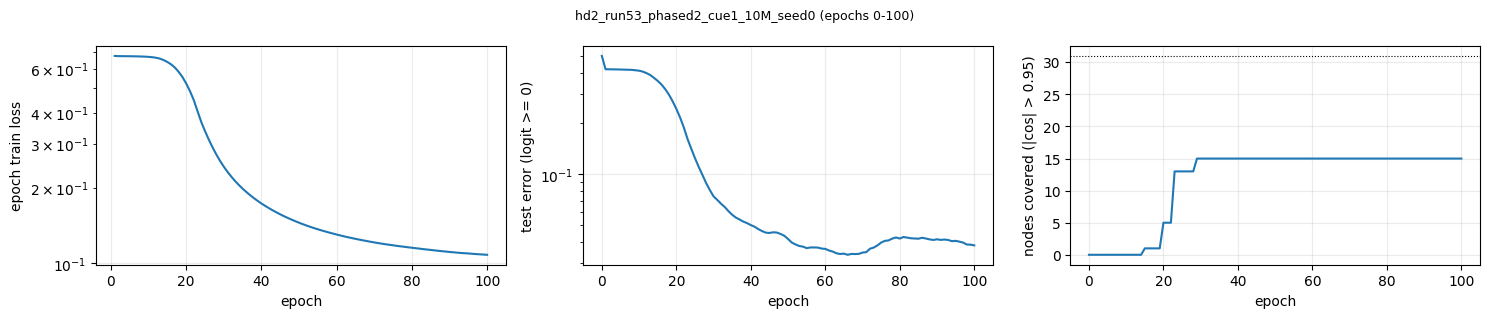

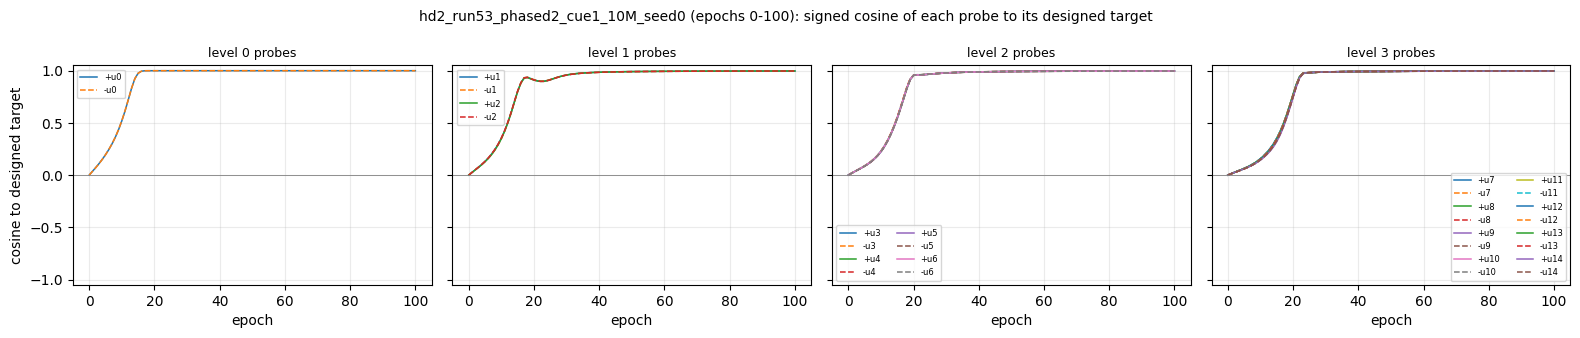

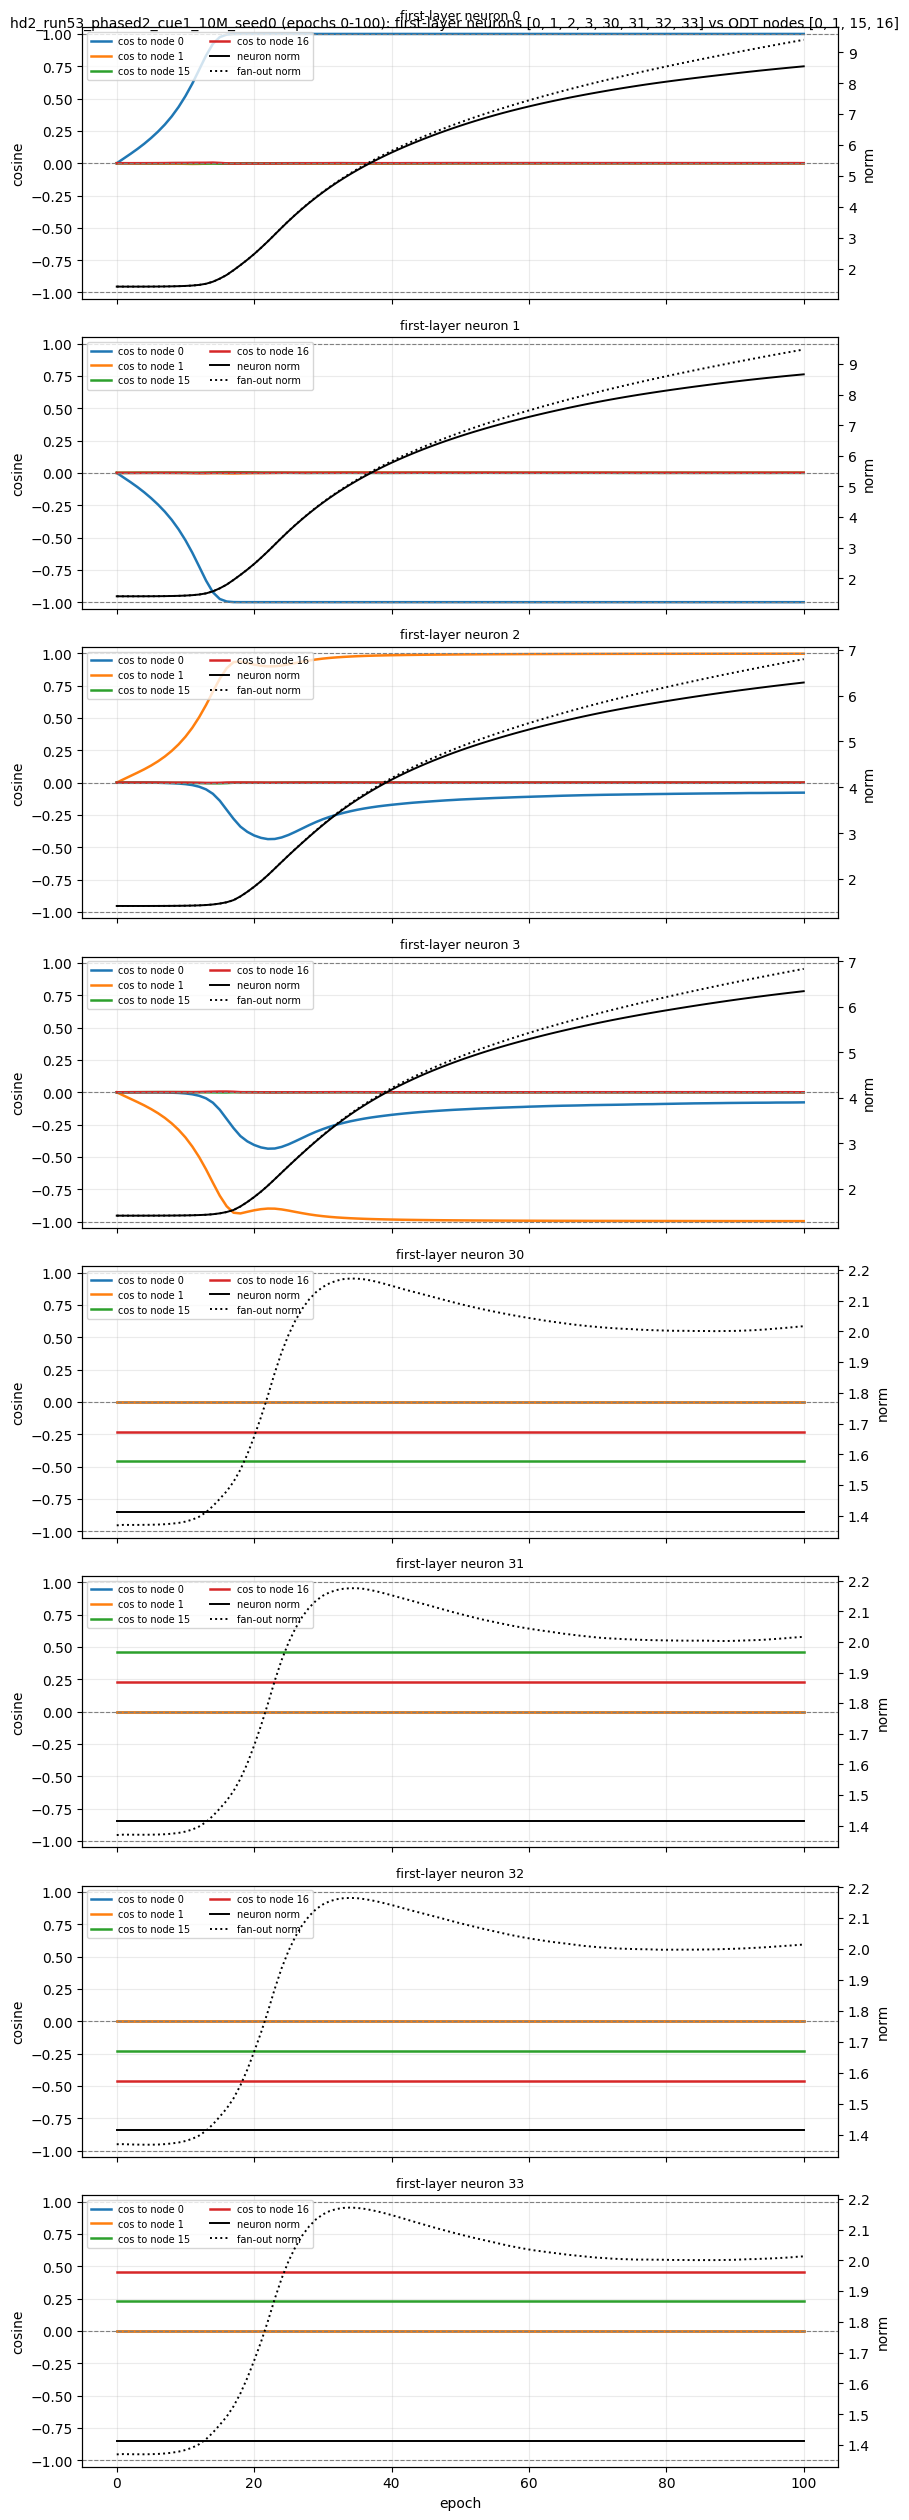

In [16]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series53 = trajectory_plots(run53, NEURON_IDS, start_epoch=0, end_epoch=100)

Visible edges: 2200 / 3842
First-layer aligned nodes: 30 / 62


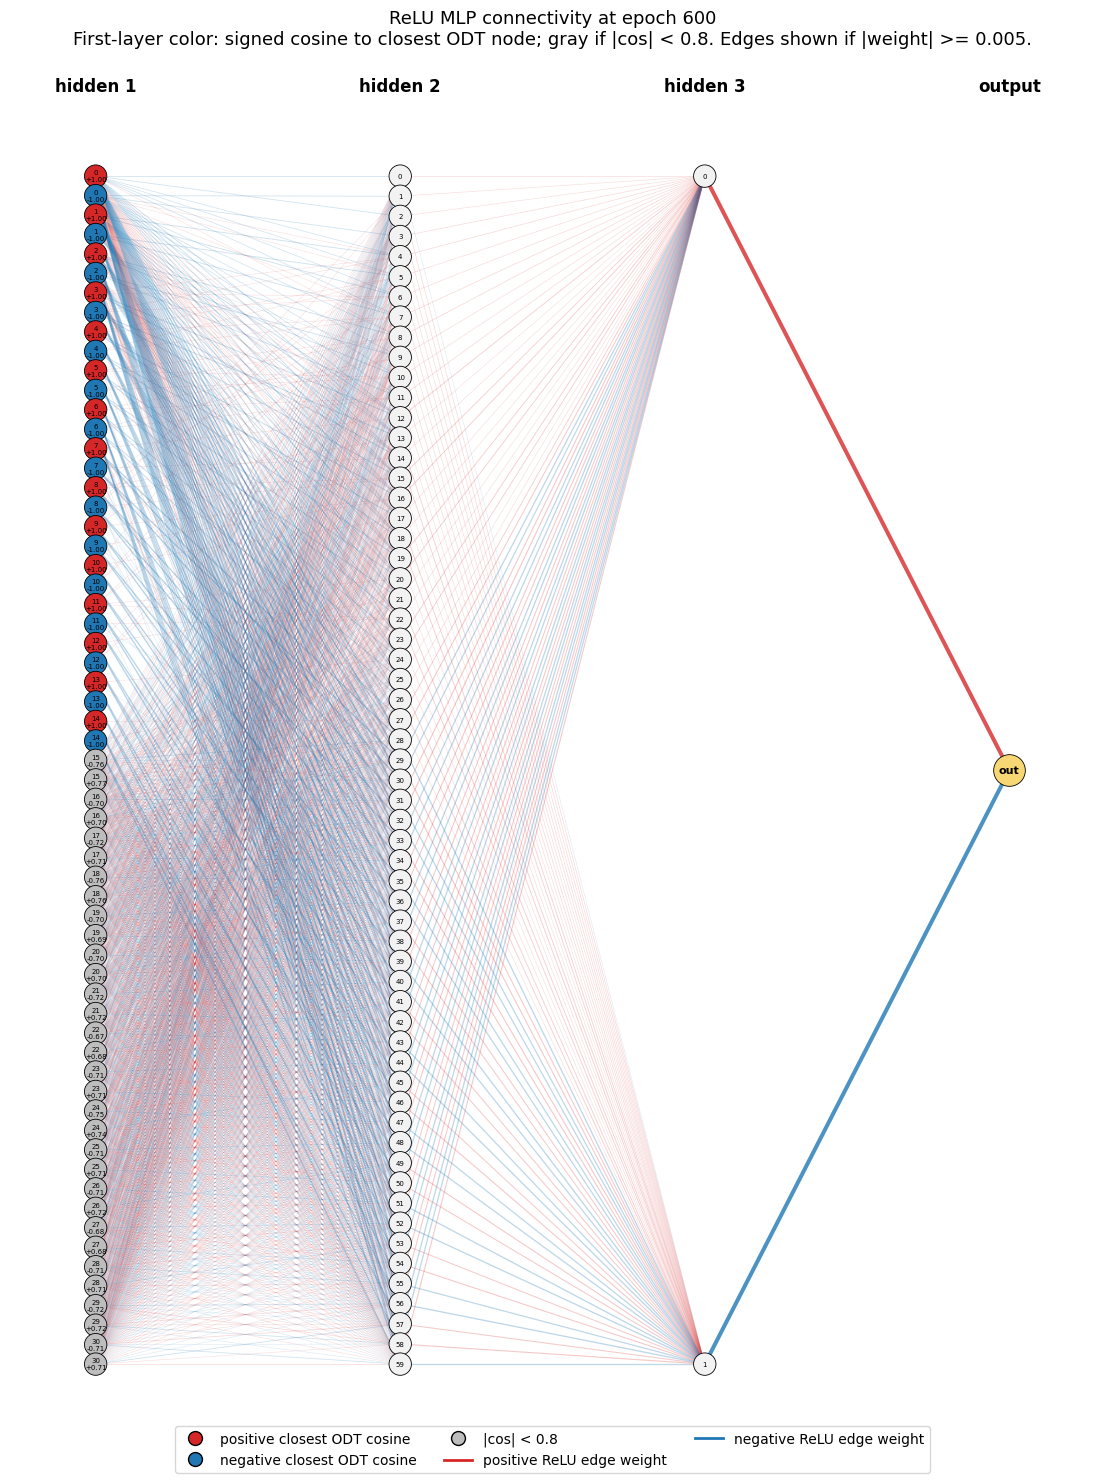

,row,group,designed_target,closest_node,level,signed_cos,norm
0,1,probe,"(0, -1)",0,0,-1.000,12.48
1,0,probe,"(0, 1)",0,0,1.000,12.49
2,3,probe,"(1, -1)",1,1,-0.999,8.83
3,2,probe,"(1, 1)",1,1,0.999,8.84
4,5,probe,"(2, -1)",2,1,-0.999,8.88
5,4,probe,"(2, 1)",2,1,0.999,8.80
6,7,probe,"(3, -1)",3,2,-0.999,6.86
7,6,probe,"(3, 1)",3,2,0.999,6.83
8,9,probe,"(4, -1)",4,2,-0.999,6.86
9,8,probe,"(4, 1)",4,2,0.999,6.85


In [30]:
GRAPH_EPOCH = 600
table53 = network_view(run53, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.005)

In [ ]:
# Cross-run cell: uses runs 51, 52 and 53 (loads the missing ones). The release phase under the three settings: cue cosine with the own normal and loss against epoch.
ensure_runs(51, 52)
from layer_lenses.designed_init import cue_row_identity
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for n in [51, 52, 53]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    cos = [np.mean([abs((W[i][rr] / np.linalg.norm(W[i][rr])) @ tree.w_list[inv[rr][0]]) for rr in cr]) for i in range(len(r["epochs"]))]
    ax[0].plot(r["epochs"], cos, lw=1, label=f"run {n}"); ax[1].plot(r["losses"], lw=0.7, label=f"run {n}")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("mean |cos| of cues with their own normal"); ax[0].axvline(500, color="k", lw=0.5, ls="--"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("epoch loss"); ax[1].axvline(500, color="k", lw=0.5, ls="--"); ax[1].legend(); plt.tight_layout(); plt.show()
print({n: f"loss {float(globals()[f'run{n}']['summary'].final_epoch_loss):.4f}, test error {float(globals()[f'run{n}']['summary'].test_error_end):.4f}" for n in [51, 52, 53]})

## 9. Run 54: run 53 with W2 negated at init

| setting | value |
|---|---|
| init | run 53's with every second-layer weight negated: probe weights +1 instead of -1 and every cue block B -> -B, so each node's four units are the same four blocks attached to the opposite probe-weight sign. By the pole rule of runs 24-25 (pole = sign of the probe weight x unit side x path sign) every probe should now be pulled to the opposite pole of its node. Negating W2 commutes with the tree flips, so the init is as equivariant as run 53's |
| protocol | run 53's: 10M points, 1000 steps per epoch, cosine over 1000 epochs; cues frozen 0-500, everything free 500-1000 |
| storage | `results/designed_init/hd2_run54_phased2_w2neg_10M/replay/` |
| script | `run_hd2_phased.py --negate-w2 --phases 500 500` |

**Findings.**
- **Collapse.** Phase 1 ends at loss 0.179 (run 53: 0.067) with 11% test error; in phase 2 the loss improves to 0.089 (test error 3-4% at epochs 577-600), then three spikes at epochs 593-604 kill both third-layer neurons: S and Sc are non-positive on every point from epoch 620 on, every logit is exactly zero, the loss sits at log 2 = 0.693 for the remaining 380 epochs (no gradient reaches a dead ReLU pair) and the test error is 50%. 15 nodes covered at the end: the 30 probes, no cues.
- **The poles did not flip.** All 30 probes end on their own node at the designed pole, as in run 53. The pole rule of runs 24-25 (pole = probe-weight sign x unit side x path sign) is not contradicted: negating W2 flips the probe weight *and* the cue block that sets the unit's side, and the two flips cancel.
- **What changed is the unit family.** With a positive probe weight each unit reads its own node's feature with the same sign as the ancestor features in its block, so instead of a veto detector (active on 3.5% of the points, five weights below -1) it becomes a dense additive unit (active on 95% of the points, five weights above +20: unit 28 reads +u_0, +u_1, +u_3, +u_7 at +26 / +24 / +23 / +21 where run 53's unit 28 vetoes them at -53 / -36 / -30 / -30). The 32 level-3 units serve only 4 distinct (leaf, sign) cells with 3% of their activity inside the cell; the readout stays small (output +-2.9 against +-22.5, level-3 readouts 13 against 74) because large readouts on dense units would blow up the logits.
- **The released cues shrink instead of capturing.** Their norm goes from 1.41 to 0.29 in the first 77 epochs of phase 2 and none reaches a normal: in the dense family the cue features are not what the units need, so the gradient removes them. The loss of that input, at lr 0.004, is what triggers the catapult.
- Reading: the sign of W2 picks the solution family (sparse veto with W2 < 0, dense additive with W2 > 0, as runs 23-25 found on the 80-30-40 design), and on this design the dense family is not just worse, it is unstable: the same two-phase protocol that gives 0.13% with the veto family ends in a dead network.


In [20]:
sr54, run54 = load_replay_run("hd2_run54_phased2_w2neg_10M", [62, 60, 2])          # ~20 s
summary54 = findings_table(run54)

,hd2_run54_phased2_w2neg_10M_seed0
final epoch loss,0.6931
test error (logit >= 0),0.4981
test error (strict),0.5019
zero-logit fraction,1.0
negative output weights,1
epochs to 0.3 / 0.1 / 0.05,103 / 577 / None
aligned rows,30 / 62
nodes covered,"15 / 31, missing [15, 16, 17, 18, 19, 20, 21, ..."
own-probe nodes / intended / opposite,15 / 15 / 0
missed by own probes,[]


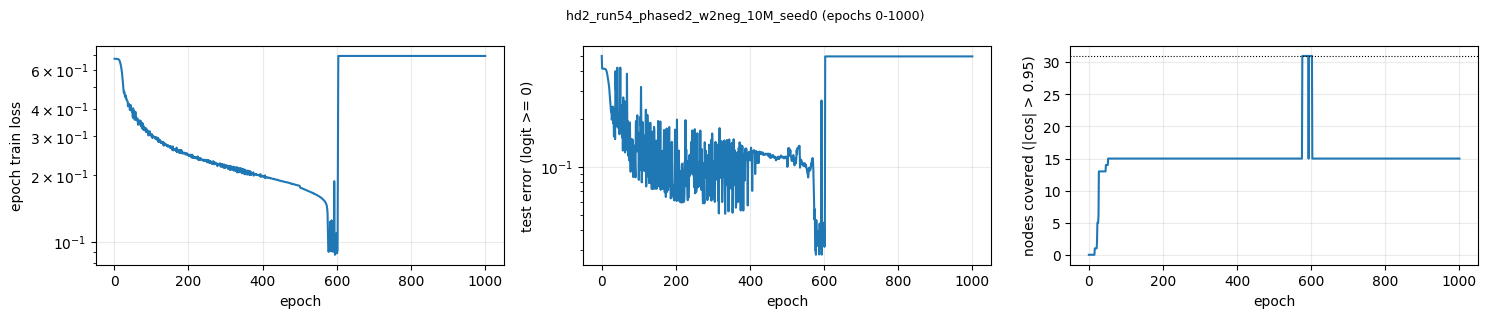

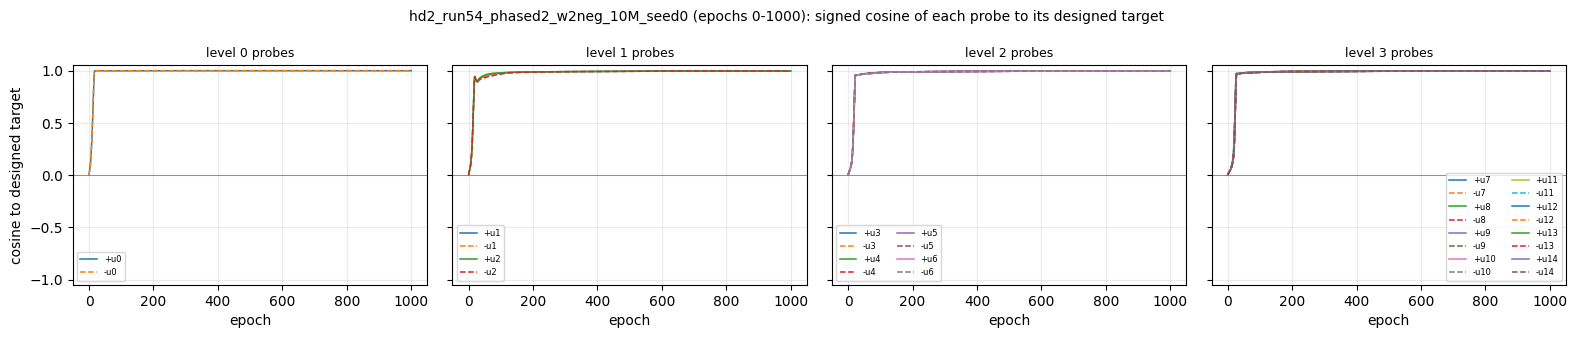

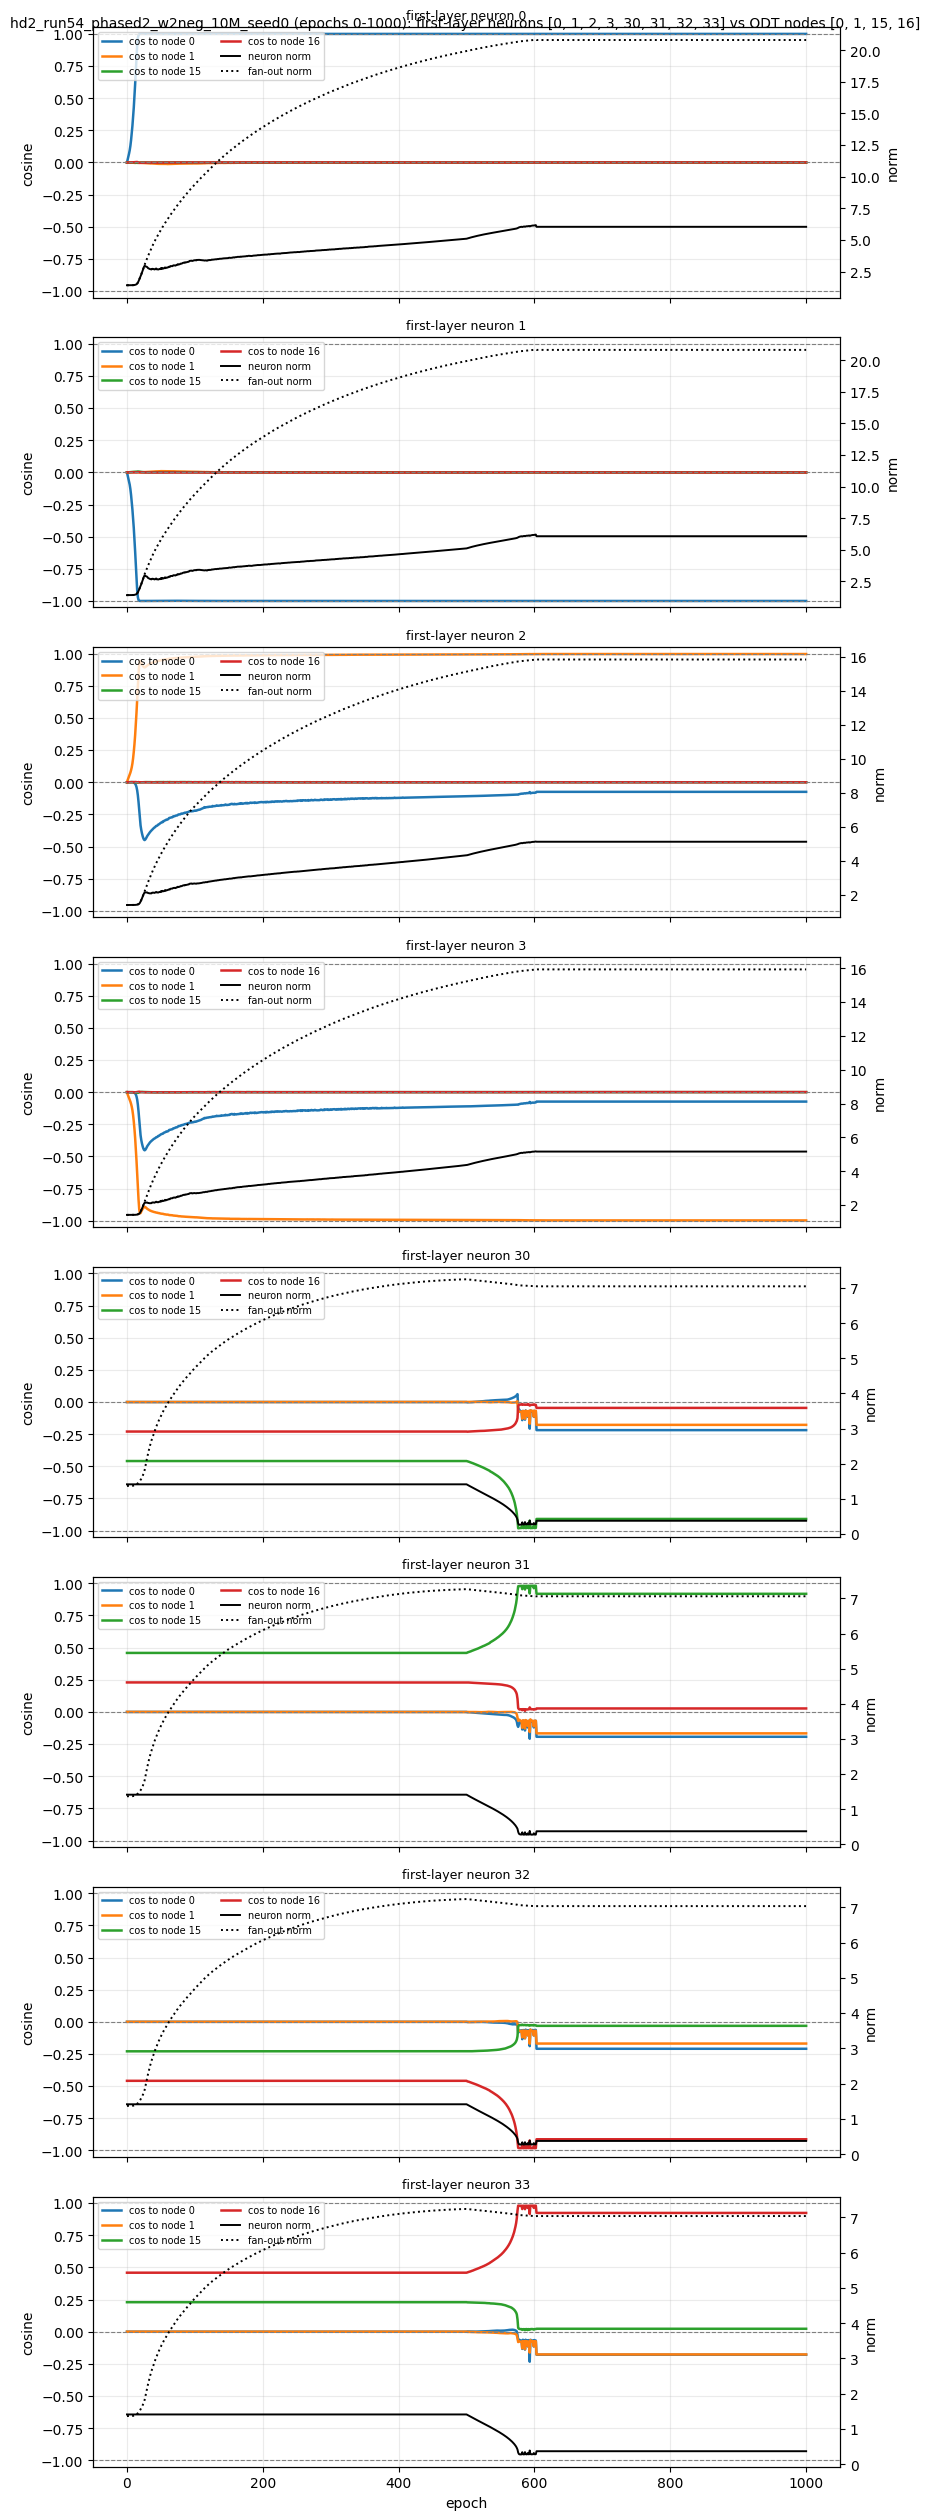

In [24]:
NEURON_IDS = [0, 1, 2, 3, 30, 31, 32, 33]
series54 = trajectory_plots(run54, NEURON_IDS, node_ids=None, end_epoch=int(run54["epochs"][-1]))

Visible edges: 2213 / 3842
First-layer aligned nodes: 62 / 62


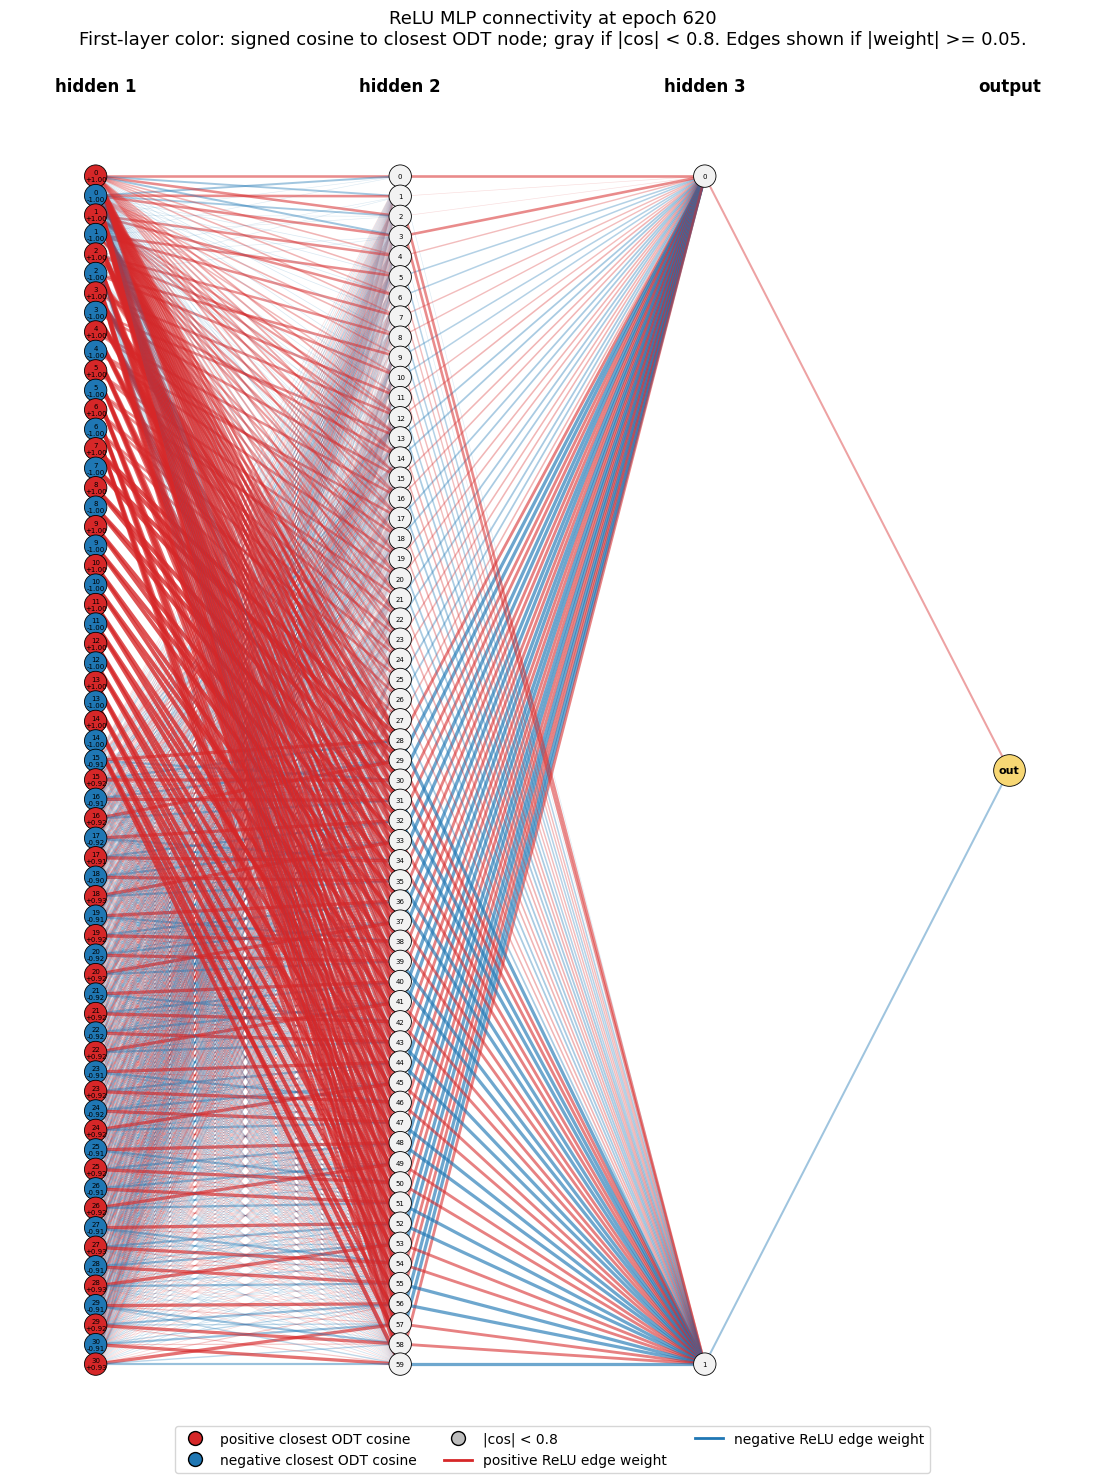

,row,group,designed_target,closest_node,level,signed_cos,norm
0,1,probe,"(0, -1)",0,0,-1.000,6.07
1,0,probe,"(0, 1)",0,0,1.000,6.04
2,3,probe,"(1, -1)",1,1,-0.997,5.16
3,2,probe,"(1, 1)",1,1,0.997,5.13
4,5,probe,"(2, -1)",2,1,-0.997,5.16
...,...,...,...,...,...,...,...
57,57,cue,,28,4,0.931,0.37
58,58,cue,,29,4,-0.913,0.38
59,59,cue,,29,4,0.925,0.37
60,60,cue,,30,4,-0.909,0.39


In [29]:
GRAPH_EPOCH = 620
table54 = network_view(run54, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 53 and 54 (loads run 53 if needed). Probe poles reached, unit regions and readouts, fates and loss under the two signs of W2.
ensure_runs(53)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, HIERARCHY_TARGETS
_rows = []
for n in [53, 54]:
    r = globals()[f"run{n}"]; W = r["W"]["hidden_layers.0.weight"]; cr = globals()[f"sr{n}"]["design"]["cue_rows"]; cid = cue_row_identity(W[0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W[-1] / np.linalg.norm(W[-1], axis=1, keepdims=True) @ tree.w_list.T; lin = probe_deviation_lineage(W[-1], tree); s = r["summary"]
    same_pole = sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and np.sign(C[p][HIERARCHY_TARGETS[p][0]]) == HIERARCHY_TARGETS[p][1] and abs(C[p]).max() > 0.95)
    opp_pole = sum(1 for p in range(30) if abs(C[p]).argmax() == HIERARCHY_TARGETS[p][0] and np.sign(C[p][HIERARCHY_TARGETS[p][0]]) == -HIERARCHY_TARGETS[p][1] and abs(C[p]).max() > 0.95)
    _rows.append({"run": n, "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes on own node, designed pole": same_pole, "own node, opposite pole": opp_pole, "deviated": int(lin.deviated.sum()),
                  "cues own": sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95), "cues on ancestor": sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0])), "w_out end": np.round(r["W"]["output_layer.weight"][-1][0], 1).tolist(), "W2 probe weights at init": float(r["W"]["hidden_layers.1.weight"][0][0, 0]), "at end (mean)": round(float(np.mean([r["W"]["hidden_layers.1.weight"][-1][u, [p for p in range(30) if r["W"]["hidden_layers.1.weight"][0][u, p] != 0][0]] for u in range(60)])), 2)})
print(pd.DataFrame(_rows).T.to_string())
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [53, 54]]; plt.axvline(500, color="k", lw=0.5, ls="--"); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()